In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
import mne

PASTA_PACIENTE = "./VP001-EEG"

# Carrega a matriz de sinal contínuo (cnt) e os marcadores de eventos (mrk)
mat_cnt = loadmat(os.path.join(PASTA_PACIENTE, 'cnt_nback.mat'), struct_as_record=False, squeeze_me=True)
mat_mrk = loadmat(os.path.join(PASTA_PACIENTE, 'mrk_nback.mat'), struct_as_record=False, squeeze_me=True)

cnt = mat_cnt['cnt_nback']
mrk = mat_mrk['mrk_nback']

In [2]:
# Informações básicas do dataset
fs = float(cnt.fs)
channels = list(cnt.clab)

print(f"Frequência de Amostragem: {fs} Hz")
print(f"Quantidade de Eletrodos: {len(channels)}")
print(f"Lista dos Eletrodos: {channels}")

Frequência de Amostragem: 200.0 Hz
Quantidade de Eletrodos: 30
Lista dos Eletrodos: ['Fp1', 'AFF5h', 'AFz', 'F1', 'FC5', 'FC1', 'T7', 'C3', 'Cz', 'CP5', 'CP1', 'P7', 'P3', 'Pz', 'POz', 'O1', 'Fp2', 'AFF6h', 'F2', 'FC2', 'FC6', 'C4', 'T8', 'CP2', 'CP6', 'P4', 'P8', 'O2', 'HEOG', 'VEOG']


In [4]:
# Preparando os dados e convertendo marcadores temporais para índices de amostra
X = cnt.x  # Matriz contínua de sinais (amostras x canais)

if mrk.time.max() > X.shape[0]:
    trials = np.round(mrk.time * fs / 1000.0).astype(int)
else:
    trials = mrk.time.astype(int)

if hasattr(mrk, 'y'):
    y = np.argmax(mrk.y, axis=0) if mrk.y.ndim > 1 else mrk.y.astype(int)
else:
    y = np.zeros(len(trials), dtype=int)

events = np.column_stack([trials, y])

print(f"- Sinal contínuo X: {X.shape[0]} amostras por {X.shape[1]} canais ({X.shape[0]/fs/60:.1f} minutos)")
print(f"- Quantidade total de marcadores: {len(trials)}")
print(f"- Formato da tabela [amostra_inicio, tipo_evento]: {events.shape}")
print(f"- 3 primeiros eventos:\n{events[:3]}")

- Sinal contínuo X: 394930 amostras por 30 canais (32.9 minutos)
- Quantidade total de marcadores: 567
- Formato da tabela [amostra_inicio, tipo_evento]: (567, 2)
- 3 primeiros eventos:
[[6000    7]
 [6026    4]
 [6472    4]]


In [ ]:
# Calcula a duração mais frequente entre marcadores consecutivos
intervalos = np.diff(trials)
valores, contagens = np.unique(intervalos, return_counts=True)
tamanho_padrao = int(valores[np.argmax(contagens)])
print(f"Tamanho padrão adotado para cada época: {tamanho_padrao} amostras ({tamanho_padrao / fs:.2f} segundos)")

# Extrai janelas contínuas de tamanho fixo da matriz X
data_f_padronizado = []
for inicio in trials:
    fim = inicio + tamanho_padrao
    fatia = X[inicio:fim, :]
    if len(fatia) < tamanho_padrao:
        faltantes = tamanho_padrao - len(fatia)
        fatia = np.pad(fatia, ((0, faltantes), (0, 0)), mode='constant', constant_values=0)
    data_f_padronizado.append(fatia)

data_f = np.asarray(data_f_padronizado)
data_y = np.array(y)

print("Formato de data_f:", data_f.shape, "-> (eventos, tempo_por_evento, canais)")
print("Formato de data_y:", data_y.shape, "-> (rótulos)")

Tamanho padrão adotado para cada época: 446 amostras (2.23 segundos)
Formato de data_f: (567, 446, 30) -> (eventos, tempo_por_evento, canais)
Formato de data_y: (567,) -> (rótulos)


In [6]:
# Exibe os nomes das classes no dataset
if hasattr(mrk, 'className'):
    print("Nomes das classes (className):")
    for i, nome in enumerate(mrk.className):
        print(f"  Código {i}: {nome}")

# Filtra apenas os estímulos de teste (códigos 0 a 4)
indices_validos = np.where(data_y < 5)[0]
data_f_final = data_f[indices_validos]
labels_validos = data_y[indices_validos]

print(f"\nTotal de marcadores originais: {len(data_y)}")
print(f"Tentativas reais mantidas:     {len(labels_validos)}")
print(f"Marcadores de sessão removidos: {len(data_y) - len(labels_validos)}")

# Agrupamento binário
data_y_final = np.array([1 if rotulo in [0, 1, 3] else 0 for rotulo in labels_validos], dtype=int)

print("\nFormato final dos arrays:")
print("data_f_final:", data_f_final.shape)
print("data_y_final:", data_y_final.shape)
print(f"Quantidade de Não-Alvos (0): {np.sum(data_y_final == 0)}")
print(f"Quantidade de Alvos (1):     {np.sum(data_y_final == 1)}")

# Salvamento dos dados em arrays NumPy
np.save('data_f_nback.npy', data_f_final)
np.save('data_y_nback.npy', data_y_final)

Nomes das classes (className):
  Código 0: 0-back target
  Código 1: 2-back target
  Código 2: 2-back non-target
  Código 3: 3-back target
  Código 4: 3-back non-target
  Código 5: 0-back session
  Código 6: 2-back session
  Código 7: 3-back session

Total de marcadores originais: 567
Tentativas reais mantidas:     540
Marcadores de sessão removidos: 27

Formato final dos arrays:
data_f_final: (540, 446, 30)
data_y_final: (540,)
Quantidade de Não-Alvos (0): 252
Quantidade de Alvos (1):     288


In [10]:
ch_names = channels
sfreq = int(fs)

# Separa os eletrodos cerebrais (eeg) dos oculares (eog)
ch_types = ['eeg' if ch not in ['HEOG', 'VEOG'] else 'eog' for ch in ch_names]

# Cria o objeto Info
info = mne.create_info(ch_names=ch_names, sfreq=sfreq, ch_types=ch_types)
info.set_montage('colin27_1005', on_missing='ignore')
info

<Info | 8 non-empty values
 bads: []
 ch_names: Fp1, AFF5h, AFz, F1, FC5, FC1, T7, C3, Cz, CP5, CP1, P7, P3, Pz, ...
 chs: 28 EEG, 2 EOG
 custom_ref_applied: False
 dig: 31 items (3 Cardinal, 28 EEG)
 highpass: 0.0 Hz
 lowpass: 100.0 Hz
 meas_date: unspecified
 nchan: 30
 projs: []
 sfreq: 200.0 Hz
>

In [8]:
# Muda de (n_épocas, n_amostras, n_canais) para (n_épocas, n_canais, n_amostras)
print("Antes da transposição:", data_f_final.shape)
data_re = data_f_final.transpose(0, 2, 1)
print("Depois da transposição:", data_re.shape)

# Cria a matriz de eventos no formato MNE: [id_epoca, 0, label]
events_mne = np.array([[i, 0, label] for i, label in enumerate(data_y_final)])
print("Formato dos eventos MNE:", events_mne.shape)

# Cria o objeto EpochsArray e salva no formato padrão .fif
epochs = mne.EpochsArray(
    data_re,
    info,
    events=events_mne,
    event_id={'non_target': 0, 'target': 1}
)

epochs.save('epochs_vp001-epo.fif', overwrite=True)

Antes da transposição: (540, 446, 30)
Depois da transposição: (540, 30, 446)
Formato dos eventos MNE: (540, 3)
Not setting metadata
540 matching events found
No baseline correction applied
0 projection items activated
Overwriting existing file.
Overwriting existing file.
Overwriting existing file.


[PosixPath('/home/pedrobornia/Documents/topicos-especiais/epochs_vp001-epo.fif')]

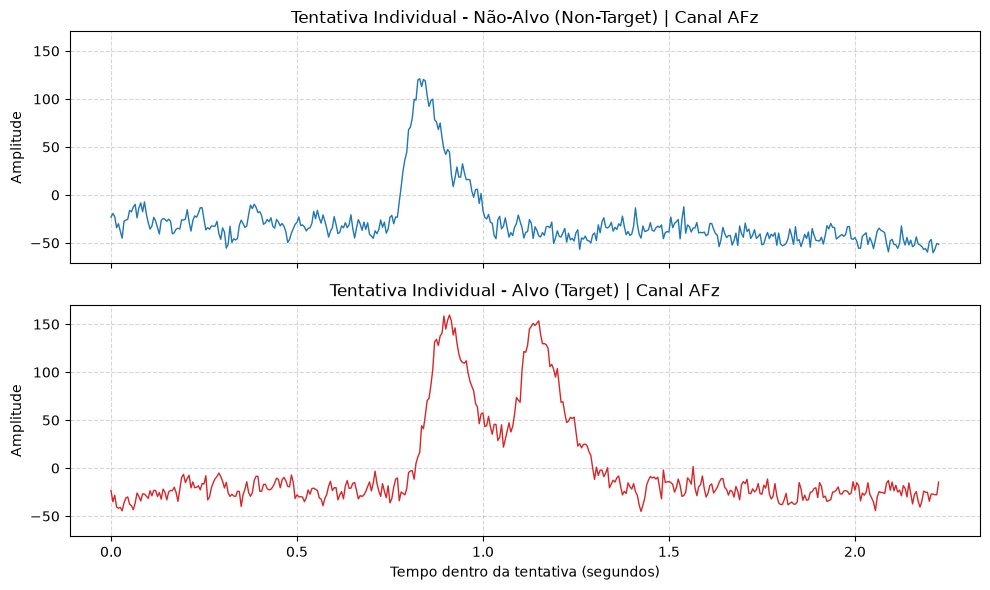

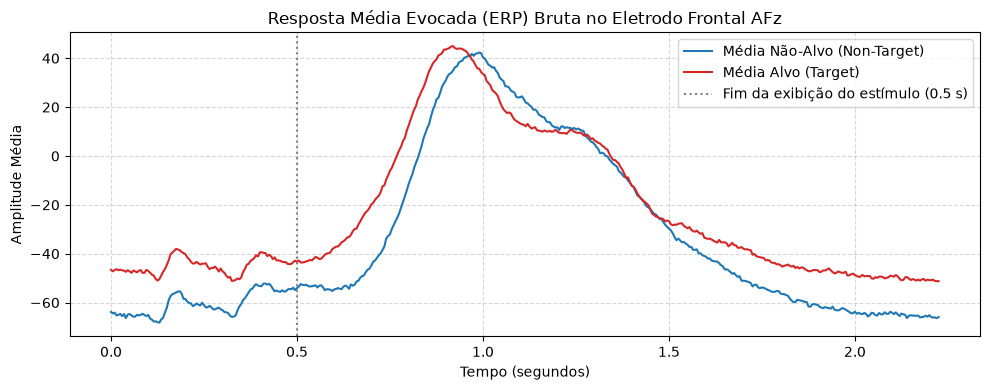

In [9]:
idx_canal = channels.index('AFz')
tempo = np.arange(data_f_final.shape[1]) / fs

idx_nontarget = np.where(data_y_final == 0)[0][0]
idx_target = np.where(data_y_final == 1)[0][0]

# Comparação de tentativas individuais
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, sharey=True)

axes[0].plot(tempo, data_f_final[idx_nontarget, :, idx_canal], color="#1f77b4", linewidth=1.0)
axes[0].set_title("Tentativa Individual - Não-Alvo (Non-Target) | Canal AFz")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(tempo, data_f_final[idx_target, :, idx_canal], color="#d62728", linewidth=1.0)
axes[1].set_title("Tentativa Individual - Alvo (Target) | Canal AFz")
axes[1].set_xlabel("Tempo dentro da tentativa (segundos)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Resposta Média Evocada (ERP) no canal AFz
media_nontarget = np.mean(data_f_final[data_y_final == 0, :, idx_canal], axis=0)
media_target = np.mean(data_f_final[data_y_final == 1, :, idx_canal], axis=0)

plt.figure(figsize=(10, 4))
plt.plot(tempo, media_nontarget, label="Média Não-Alvo (Non-Target)", color="#1f77b4", linewidth=1.5)
plt.plot(tempo, media_target, label="Média Alvo (Target)", color="#d62728", linewidth=1.5)
plt.title("Resposta Média Evocada (ERP) Bruta no Eletrodo Frontal AFz")
plt.xlabel("Tempo (segundos)")
plt.ylabel("Amplitude Média")
plt.axvline(0.5, color="gray", linestyle=":", label="Fim da exibição do estímulo (0.5 s)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()